# 🏗️ Concrete Strength Prediction

**Regression & Classification | Classical Machine Learning + Deep Learning**

Predict concrete compressive strength from its mixture ingredients and curing age, then classify mixtures into four strength categories. The notebook follows the two problems from the original course assignment with clear, beginner-friendly Python code.


<img src="concrete_strength_animation.gif" width="750">
*The animation reveals measured samples by age. Each point is a separate observation; it is not a time series of a single concrete batch.*

**Problem types**

| Task | Question | Target | Type |
|---|---|---|---|
| **Regression** | How strong will a given concrete mixture be? | `Strength` (MPa) | Continuous prediction |
| **Classification** | Which strength category does the mixture belong to? | `ConcreteClass` | Multiclass prediction |

We compare **7 classical algorithms and 1 Artificial Neural Network (PyTorch)** for **each task**. Model performance is evaluated on held-out data rather than the training data.

**Data dictionary**

The dataset contains **1,030 observations**, **8 quantitative predictors**, and **1 continuous output**

| Feature | Description | Unit |
|---|---|---|
| `Cement` | Cement content | kg/m³ |
| `Slag` | Blast furnace slag | kg/m³ |
| `FlyAsh` | Fly ash | kg/m³ |
| `Water` | Mixing water | kg/m³ |
| `Plasticizer` | Superplasticizer | kg/m³ |
| `CoarseAgg` | Coarse aggregate | kg/m³ |
| `FineAgg` | Fine aggregate | kg/m³ |
| `Age` | Curing age | days |
| `Strength` | Measured compressive strength | MPa |

For classification, we additionally derive `ConcreteClass` from strength thresholds and `Green` from an **assignment-specific ingredient rule**. `Green` is an illustrative label, **not a verified environmental certification**

**Data loading**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVR, SVC
from sklearn.naive_bayes import GaussianNB
import torch
from torch import nn

In [2]:
df = pd.read_excel("Concrete_Data.xls")

In [3]:
df.columns = ["Cement", "Slag", "FlyAsh", "Water", "Plasticizer",
              "CoarseAgg", "FineAgg", "Age", "Strength"]
display(df.head())

,Cement,Slag,FlyAsh,Water,Plasticizer,CoarseAgg,FineAgg,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


**Data overview**

In [4]:
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
display(df.describe().round(2))

Shape: (1030, 9)
Missing values: 0
Duplicate rows: 25


,Cement,Slag,FlyAsh,Water,Plasticizer,CoarseAgg,FineAgg,Age,Strength
count,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00
mean,281.17,73.90,54.19,181.57,6.20,972.92,773.58,45.66,35.82
std,104.51,86.28,64.00,21.36,5.97,77.75,80.18,63.17,16.71
min,102.00,0.00,0.00,121.75,0.00,801.00,594.00,1.00,2.33
25%,192.38,0.00,0.00,164.90,0.00,932.00,730.95,7.00,23.71
50%,272.90,22.00,0.00,185.00,6.35,968.00,779.51,28.00,34.44
75%,350.00,142.95,118.27,192.00,10.16,1029.40,824.00,56.00,46.14
max,540.00,359.40,200.10,247.00,32.20,1145.00,992.60,365.00,82.60


**Exploratory data analysis**

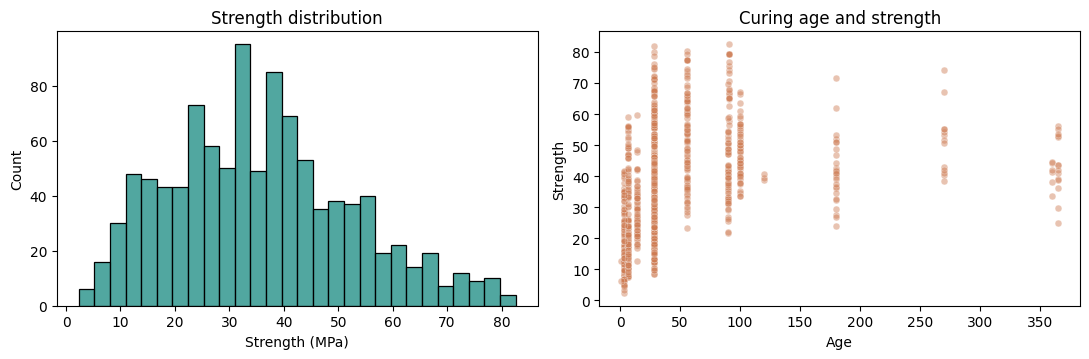

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.7))
sns.histplot(df["Strength"], bins=28, color="#178a80", ax=ax[0])
ax[0].set_title("Strength distribution")
ax[0].set_xlabel("Strength (MPa)")
sns.scatterplot(data=df, x="Age", y="Strength", alpha=.45,
                s=24, color="#ce7b52", ax=ax[1])
ax[1].set_title("Curing age and strength")
plt.tight_layout()
plt.show()

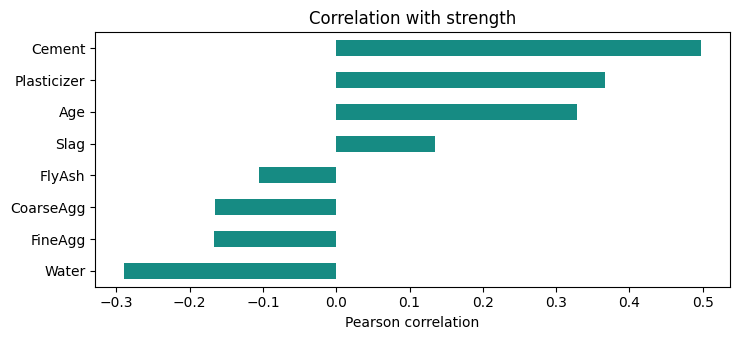

In [6]:
corr = df.corr(numeric_only=True)["Strength"].drop("Strength").sort_values()
corr.plot.barh(figsize=(7.5, 3.5), color="#168b83", title="Correlation with strength")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

---

**Regression | Predict concrete strength (MPa)**

We use the original 8 numerical inputs to predict the **continuous** strength value. The dataset is split into **80% training / 20% testing** (seed 42). Smaller **MAE** and **RMSE**, and larger **R²**, indicate better test predictions. Scaling is learned from training data only.

In [7]:
X = df.drop(columns="Strength")
y = df["Strength"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("Training:", len(X_train), "| Test:", len(X_test))

Training: 824 | Test: 206


**Seven classical regression models**

In [8]:
reg_models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "KNN": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=120, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "SVR": SVR()
}

reg_rows, reg_predictions = [], {}
for name, model in reg_models.items():
    pipeline = make_pipeline(StandardScaler(), model)
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    reg_predictions[name] = pred
    reg_rows.append([name, mean_absolute_error(y_test, pred),
                     np.sqrt(mean_squared_error(y_test, pred)), r2_score(y_test, pred)])
reg_results = pd.DataFrame(reg_rows, columns=["Model", "MAE", "RMSE", "R2"]).sort_values("MAE")
display(reg_results.round(3))
print("REG_RESULTS_JSON:", reg_results.to_json(orient="records", double_precision=9))

,Model,MAE,RMSE,R2
4,Random Forest,3.759,5.528,0.881
5,Gradient Boosting,4.103,5.544,0.881
3,Decision Tree,4.525,6.905,0.815
2,KNN,6.765,8.510,0.719
6,SVR,7.515,9.433,0.655
0,Linear Regression,7.745,9.797,0.628
1,Ridge,7.752,9.796,0.628


REG_RESULTS_JSON: [{"Model":"Random Forest","MAE":3.759183515,"RMSE":5.52846835,"R2":0.881388415},{"Model":"Gradient Boosting","MAE":4.102828089,"RMSE":5.544033705,"R2":0.880719575},{"Model":"Decision Tree","MAE":4.524613573,"RMSE":6.905008585,"R2":0.814968402},{"Model":"KNN","MAE":6.765328907,"RMSE":8.509829029,"R2":0.718965832},{"Model":"SVR","MAE":7.515448729,"RMSE":9.432832388,"R2":0.654695936},{"Model":"Linear Regression","MAE":7.745392872,"RMSE":9.796707832,"R2":0.627541606},{"Model":"Ridge","MAE":7.751761422,"RMSE":9.796410931,"R2":0.627564181}]


**Best regression model | Actual vs predicted**

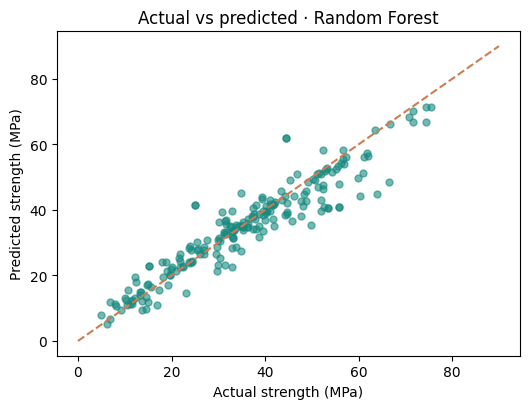

In [9]:
best_reg = reg_results.iloc[0]["Model"]
plt.figure(figsize=(5.4, 4.2))
plt.scatter(y_test, reg_predictions[best_reg], alpha=0.6, s=25, color="#178a80")
plt.plot([0, 90], [0, 90], "--", color="#d17b52")
plt.xlabel("Actual strength (MPa)")
plt.ylabel("Predicted strength (MPa)")
plt.title(f"Actual vs predicted · {best_reg}")
plt.tight_layout()
plt.show()

**Deep learning | ANN regression**

A compact **PyTorch Artificial Neural Network** with two hidden layers (32 and 16 neurons). The 8 inputs and the numerical target are standardized using training data only.

In [10]:
torch.manual_seed(42)
torch.set_num_threads(2)
scale_x, scale_y = StandardScaler(), StandardScaler()
xtr = torch.tensor(scale_x.fit_transform(X_train), dtype=torch.float32)
xte = torch.tensor(scale_x.transform(X_test), dtype=torch.float32)
ytr = torch.tensor(scale_y.fit_transform(y_train.to_numpy().reshape(-1, 1)), dtype=torch.float32)

ann_reg = nn.Sequential(nn.Linear(8, 32), nn.ReLU(), nn.Linear(32, 16),
                        nn.ReLU(), nn.Linear(16, 1))
optimizer = torch.optim.Adam(ann_reg.parameters(), lr=0.01)
for epoch in range(180):
    optimizer.zero_grad()
    loss = nn.MSELoss()(ann_reg(xtr), ytr)
    loss.backward()
    optimizer.step()

with torch.no_grad():
    prediction = scale_y.inverse_transform(ann_reg(xte).numpy()).ravel()
ann_reg_scores = {"MAE": mean_absolute_error(y_test, prediction),
                  "RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
                  "R2": r2_score(y_test, prediction)}
print("ANN Regression:", {k: round(v, 3) for k, v in ann_reg_scores.items()})
print("ANN_REG_JSON:", pd.Series(ann_reg_scores).to_json())

ANN Regression: {'MAE': 4.163, 'RMSE': np.float64(5.95), 'R2': 0.863}
ANN_REG_JSON: {"MAE":4.1628076317,"RMSE":5.9500415969,"R2":0.8626092614}


---

**Classification | Predict concrete class**

Here we transform measured strength into 4 categories (thresholds from the assignment):

| Class | Strength |
|---|---|
| non-structural | less than 17 MPa |
| residential | 17 to less than 28 MPa |
| commercial | 28 to less than 70 MPa |
| high-strength | 70 MPa or more |

The assignment also creates `Green` using `Slag`, `FlyAsh`, and `Plasticizer`, and converts `Plasticizer` to **yes/no**. Crucially, `Strength` is **removed** from classification features to prevent target leakage.

**Create classification labels**

In [11]:
def green_classifier(s):
    if (s.Slag + s.FlyAsh < 150) and (s.Plasticizer < 10):
        return "n/a"
    return "green"

def strength_classifier(x):
    if x < 17: return "non-structural"
    if x < 28: return "residential"
    if x < 70: return "commercial"
    return "high-strength"

df_class = df.copy()
df_class["Green"] = df_class.apply(green_classifier, axis=1)
df_class["ConcreteClass"] = df_class["Strength"].apply(strength_classifier)
df_class["Plasticizer"] = df_class["Plasticizer"].apply(lambda x: "yes" if x > 0 else "no")
display(df_class[["Strength", "Green", "Plasticizer", "ConcreteClass"]].head())

,Strength,Green,Plasticizer,ConcreteClass
0,79.986111,n/a,yes,high-strength
1,61.887366,n/a,yes,commercial
2,40.269535,n/a,no,commercial
3,41.052780,n/a,no,commercial
4,44.296075,n/a,no,commercial


**Class distribution and train-test split**

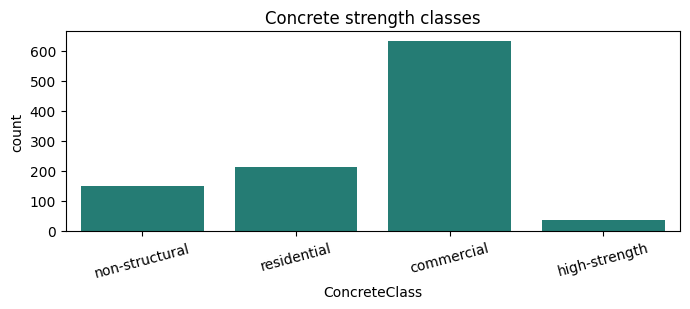

Training: 824 | Test: 206


In [12]:
order = ["non-structural", "residential", "commercial", "high-strength"]
fig, ax = plt.subplots(figsize=(7, 3.2))
sns.countplot(data=df_class, x="ConcreteClass", order=order, color="#178a80", ax=ax)
ax.set_title("Concrete strength classes")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

Xc = pd.get_dummies(df_class.drop(columns=["Strength", "ConcreteClass"]), dtype=int)
yc = df_class["ConcreteClass"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, random_state=42, stratify=yc)
print("Training:", len(Xc_train), "| Test:", len(Xc_test))

**Seven classical classification models**

In [13]:
cls_models = {
    "Logistic Regression": LogisticRegression(max_iter=1500),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=120, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVC": SVC(),
    "Naive Bayes": GaussianNB()
}

cls_rows, cls_fitted = [], {}
for name, model in cls_models.items():
    pipeline = make_pipeline(StandardScaler(), model)
    pipeline.fit(Xc_train, yc_train)
    pred = pipeline.predict(Xc_test)
    cls_fitted[name] = pipeline
    cls_rows.append([name, accuracy_score(yc_test, pred),
                     f1_score(yc_test, pred, average="macro")])
cls_results = pd.DataFrame(cls_rows, columns=["Model", "Accuracy", "Macro F1"]).sort_values("Macro F1", ascending=False)
display(cls_results.round(3))
print("CLS_RESULTS_JSON:", cls_results.to_json(orient="records", double_precision=9))

,Model,Accuracy,Macro F1
3,Random Forest,0.879,0.804
4,Gradient Boosting,0.854,0.768
2,Decision Tree,0.835,0.759
1,KNN,0.733,0.622
0,Logistic Regression,0.786,0.541
6,Naive Bayes,0.612,0.503
5,SVC,0.718,0.491


CLS_RESULTS_JSON: [{"Model":"Random Forest","Accuracy":0.878640777,"Macro F1":0.804280588},{"Model":"Gradient Boosting","Accuracy":0.854368932,"Macro F1":0.76774907},{"Model":"Decision Tree","Accuracy":0.834951456,"Macro F1":0.759102681},{"Model":"KNN","Accuracy":0.733009709,"Macro F1":0.622318723},{"Model":"Logistic Regression","Accuracy":0.786407767,"Macro F1":0.541236577},{"Model":"Naive Bayes","Accuracy":0.611650485,"Macro F1":0.502628675},{"Model":"SVC","Accuracy":0.718446602,"Macro F1":0.491448544}]


**Confusion matrix | Best classical classifier**

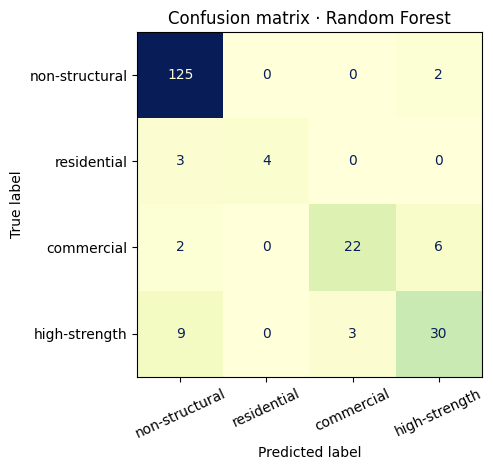

In [14]:
best_cls = cls_results.iloc[0]["Model"]
fig, ax = plt.subplots(figsize=(7, 4.8))
ConfusionMatrixDisplay.from_estimator(
    cls_fitted[best_cls], Xc_test, yc_test, display_labels=order,
    cmap="YlGnBu", xticks_rotation=25, ax=ax, colorbar=False)
ax.set_title(f"Confusion matrix · {best_cls}")
plt.tight_layout()
plt.show()

**Deep learning | ANN classification**

We train a small **PyTorch neural network** with two hidden layers. Its output has 4 neurons, one for each class. We use **Macro F1** in addition to Accuracy because the class frequencies differ substantially.

In [15]:
encoder = LabelEncoder()
yc_tr = encoder.fit_transform(yc_train)
yc_te = encoder.transform(yc_test)
scale_c = StandardScaler()
xc_tr = torch.tensor(scale_c.fit_transform(Xc_train), dtype=torch.float32)
xc_te = torch.tensor(scale_c.transform(Xc_test), dtype=torch.float32)
yc_tensor = torch.tensor(yc_tr, dtype=torch.long)

ann_cls = nn.Sequential(nn.Linear(Xc_train.shape[1], 32), nn.ReLU(),
                        nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, len(encoder.classes_)))
weights = len(yc_tr) / (len(encoder.classes_) * np.bincount(yc_tr))
criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32))
optimizer = torch.optim.Adam(ann_cls.parameters(), lr=0.01)
for epoch in range(180):
    optimizer.zero_grad()
    loss = criterion(ann_cls(xc_tr), yc_tensor)
    loss.backward()
    optimizer.step()

with torch.no_grad():
    ann_classes = ann_cls(xc_te).argmax(dim=1).numpy()
ann_cls_scores = {"Accuracy": accuracy_score(yc_te, ann_classes),
                  "Macro F1": f1_score(yc_te, ann_classes, average="macro")}
print("ANN Classification:", {k: round(v, 3) for k, v in ann_cls_scores.items()})
print("ANN_CLS_JSON:", pd.Series(ann_cls_scores).to_json())

ANN Classification: {'Accuracy': 0.816, 'Macro F1': 0.716}
ANN_CLS_JSON: {"Accuracy":0.8155339806,"Macro F1":0.7160505527}


**Model comparison**

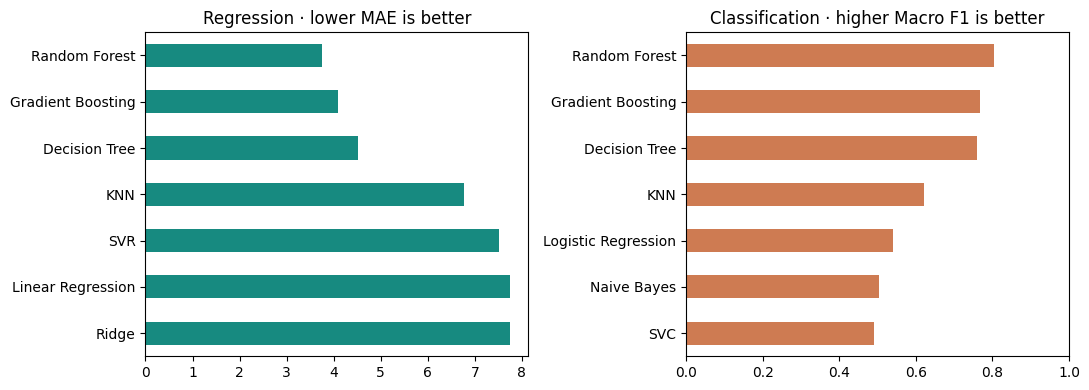

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
reg_results.sort_values("MAE", ascending=False).plot.barh(
    x="Model", y="MAE", legend=False, color="#178a80", ax=ax[0])
ax[0].set_title("Regression · lower MAE is better")
ax[0].set_ylabel("")
cls_results.sort_values("Macro F1").plot.barh(
    x="Model", y="Macro F1", legend=False, color="#ce7b52", ax=ax[1])
ax[1].set_title("Classification · higher Macro F1 is better")
ax[1].set_ylabel("")
ax[1].set_xlim(0, 1)
plt.tight_layout()
plt.show()

**Conclusion**

- **Regression:** Concrete strength is a continuous variable measured in MPa. We compare seven conventional methods with a small neural network using MAE, RMSE and R².
- **Classification:** Strength is converted into four assignment-defined categories. We compare seven conventional classifiers with a neural network using Accuracy and **Macro F1**.
- **Important:** `Strength` is never included among the classification features. The `Green` label is a rule-based exercise feature, not proof of environmental performance.

**Limitations:** The dataset is relatively small and contains repeated observations. A single random train-test split is suitable for this introductory study but does not prove performance on unseen mixtures or production concrete. More robust validation should group identical recipes and test across multiple splits. Neural-network scores are illustrative, not guaranteed improvements over classical ML.

**Source:** [UCI Concrete Compressive Strength](https://archive.ics.uci.edu/ml/datasets/Concrete+Compressive+Strength). Data attribution: **I-Cheng Yeh**, *Modeling of strength of high performance concrete using artificial neural networks*, Cement and Concrete Research, 28(12), 1797–1808 (1998). Dataset reuse requires retention of this credit.